# Tennis network analysis: full pipeline

Runs every computation of the study in order, from the raw files to the tables and figures of the report,
and shows the main results after each step.

> [!NOTE]
> All cells in this notebook are pre-rendered with the full experimental results, tables, and figures from `results/` and `report/`. You can view them directly on GitHub or in any Jupyter viewer.


**Before running**
1. From the repository root: `python -m venv .venv`, activate it, then `pip install -e ".[dev,notebook]"`.
2. Open this notebook with the `.venv` kernel (VS Code or `jupyter lab`).
3. Choose the settings in the next cell, then *Run All*.

**Running time.** With `QUICK = False` (the settings used in the report) the whole notebook takes about
one to two hours, most of it in the null models. `QUICK = True` uses few samples and finishes in minutes:
use it to check that everything works, **not** for the numbers of the report.

**Outputs.** Every step writes to `results/` and `report/`, overwriting the files committed in the
repository. `git diff --stat` shows what changed; `git checkout -- results report` restores the committed version.

In [1]:
# Settings
# Set RECOMPUTE = True to rerun the entire pipeline from scratch (takes ~1-2 hours due to null models)
# Set RECOMPUTE = False to load and visualize the committed results in results/ and report/ in seconds
RECOMPUTE = False
QUICK = False  # True: few samples, for a quick test run when RECOMPUTE=True
DOWNLOAD = False  # True: download tennis-data.co.uk again (the files are committed)
SKIP = set()  # additional steps to skip when RECOMPUTE is True

In [2]:
import subprocess
import sys
import time

import pandas as pd
from IPython.display import Image, Markdown, display

from tennis_networks.config import REPORT, ROOT, TABLES, load_config

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)

# Arguments of each step: full run (report) and quick run (test only).
ARGS = {
    "analysis": ([], ["--samples", "10"]),
    "hypotheses": (["--null", "200"], ["--null", "20", "--perm", "199"]),
    "structure": ([], ["--sw-samples", "3", "--perm", "199"]),
    "triads": ([], ["--null", "5", "--perm", "199"]),
    "levels": ([], ["--perm", "199"]),
}


def run(module, *extra):
    """Run one pipeline step as `python -m tennis_networks.<module>` and print its output."""
    if not RECOMPUTE:
        print(f"[{module}] (using precomputed results)")
        return
    if module in SKIP:
        print(f"skipped: {module}")
        return
    full, quick = ARGS.get(module, ([], []))
    cmd = [sys.executable, "-m", f"tennis_networks.{module}", *(quick if QUICK else full), *extra]
    start = time.time()
    proc = subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True)
    print(proc.stdout[-4000:])
    if proc.returncode != 0:
        print(proc.stderr[-4000:])
        raise RuntimeError(f"{module} failed with exit code {proc.returncode}")
    print(f"[{module}] done in {(time.time() - start) / 60:.1f} min")


def table(name, **kwargs):
    return pd.read_csv(TABLES / name, **kwargs)


cfg = load_config()
print(f"Repository: {ROOT}")
print(f"Seed: {cfg['seed']}, recompute: {RECOMPUTE}, quick mode: {QUICK}")

Repository: D:\Actual\03_Sviluppo_Software\Repositories\tennis-network-analysis
Seed: 20261115, recompute: False, quick mode: False


## 1. Data

Michieli (2018) networks from MATLAB to CSV edge lists, then the nine comparative networks from
tennis-data.co.uk (edges from loser to winner, weight = wins, walkovers excluded).

In [3]:
if DOWNLOAD:
    run("download")
run("michieli")
run("tennisdata")
display(table("td_networks_summary.csv"))
display(table("td_validity_michieli.csv"))

[michieli] (using precomputed results)
[tennisdata] (using precomputed results)


,network,matches,players,edges,first,last
0,td_atp_2000_2006,20265,803,14997,2000-01-03,2006-11-19
1,td_atp_2007_2012,16114,651,11665,2007-01-01,2012-11-12
2,td_atp_2013_2018,15661,602,11324,2012-12-31,2018-11-18
3,td_atp_2019_2025,16932,630,12599,2018-12-31,2025-11-16
4,td_atp_clay,22117,1191,17940,2000-02-21,2025-07-26
5,td_atp_grass,7693,881,7128,2000-06-12,2025-07-13
6,td_atp_hard,37477,1387,27623,2000-01-03,2025-11-16
7,td_atp_2007_2025,48707,1280,32296,2007-01-01,2025-11-16
8,td_wta_2007_2025,45112,1319,31616,2006-12-31,2025-11-08


,check,total,found_in_michieli,share
0,"ATP loser-winner pairs, 2000 to Aug 2017",32297,31513,0.976
1,"ATP players, 2000 to Aug 2017",1360,1350,0.993


## 2. Reproduction of Michieli (2018)

In [4]:
run("reproduce")
display(table("michieli_reproduction.csv")[["network", "measure", "paper", "ours"]])

[reproduce] (using precomputed results)


,network,measure,paper,ours
0,M1 directed,largest strongly connected component,2428.000,2428.000
1,M1 directed,average distance,3.480,3.470
2,M1 directed,diameter,10.000,9.000
3,M1 directed,top-10 PageRank players shared with the paper,10.000,10.000
4,M3 undirected,connected components,1.000,1.000
5,M3 undirected,average distance,3.340,3.340
6,M3 undirected,diameter,8.000,8.000
7,M3 undirected,average clustering,0.070,0.311
8,M3 undirected,degree assortativity,-0.008,-0.004
9,M4 extended,average distance,3.640,3.630


## 3. Measures of every network

Degrees, PageRank, betweenness, k-cores, components, distances, clustering, assortativity, triad census,
Louvain communities, robustness, and directed null models. The longest step.

In [5]:
run("analysis")
cols = [
    "nodes",
    "edges",
    "density",
    "reciprocity",
    "giant_fraction",
    "avg_path_giant",
    "diameter_giant",
    "max_kcore",
    "modularity",
    "top10_pagerank_share",
    "gini_in_strength",
    "spearman_pagerank_atp_rank",
]
display(table("global_measures.csv", index_col="network")[cols].T)

[analysis] (using precomputed results)


network,example_karate,atp_wins_direct,atp_matches_undirect,td_atp_2000_2006,td_atp_2007_2012,td_atp_2013_2018,td_atp_2019_2025,td_atp_clay,td_atp_grass,td_atp_hard,td_atp_2007_2025,td_wta_2007_2025
nodes,34.000,4245.000,4245.000,803.000,651.000,602.000,630.000,1191.000,881.000,1387.000,1280.000,1319.000
edges,78.000,101436.000,85084.000,14997.000,11665.000,11324.000,12599.000,17940.000,7128.000,27623.000,32296.000,31616.000
density,0.139,0.006,0.009,0.023,0.028,0.031,0.032,0.013,0.009,0.014,0.020,0.018
reciprocity,NaN,0.322,NaN,0.300,0.295,0.295,0.288,0.207,0.086,0.282,0.346,0.321
giant_fraction,1.000,0.572,1.000,0.640,0.637,0.636,0.695,0.694,0.673,0.658,0.658,0.622
avg_path_giant,2.408,3.209,3.340,2.570,2.517,2.447,2.514,2.940,3.285,2.842,2.632,2.620
diameter_giant,5.000,9.000,8.000,7.000,6.000,5.000,6.000,9.000,8.000,7.000,6.000,7.000
max_kcore,4.000,101.000,79.000,73.000,67.000,67.000,64.000,48.000,21.000,69.000,95.000,90.000
modularity,0.428,0.536,0.522,0.145,0.126,0.113,0.114,0.375,0.375,0.382,0.295,0.296
top10_pagerank_share,0.569,0.065,0.020,0.143,0.222,0.195,0.171,0.123,0.143,0.123,0.139,0.101


## 4. Hypotheses H1-H4 (network level)

* H1: prestige more concentrated in 2007-2018 than in 2019-2025 (season permutation)
* H2: assortativity against the configuration model (with undirected clustering and transitivity)
* H3: grass more centralized than clay and hard (match permutation, size-aware)
* H4: WTA prestige less concentrated than ATP (paired seasons)

In [6]:
run("hypotheses")
display(table("hypothesis_tests.csv"))
display(table("null_undirected.csv").pivot(index="network", columns="statistic", values="z"))

[hypotheses] (using precomputed results)


,hypothesis,statistic,comparison,value_a,value_b,diff,p_value,z,perm_mean_diff
0,H1,top10_pagerank_share,ATP 2007-2018 vs 2019-2025 (season means),0.265,0.234,0.031,0.060,NaN,NaN
1,H1,degree_centralization,ATP 2007-2018 vs 2019-2025 (season means),0.144,0.145,-0.001,0.757,NaN,NaN
2,H2,degree_assortativity,td_atp_2000_2006 vs configuration model,-0.031,-0.183,0.152,0.005,24.600,NaN
3,H2,degree_assortativity,td_atp_2007_2012 vs configuration model,-0.036,-0.187,0.151,0.005,20.263,NaN
4,H2,degree_assortativity,td_atp_2013_2018 vs configuration model,-0.036,-0.175,0.138,0.005,17.733,NaN
5,H2,degree_assortativity,td_atp_2019_2025 vs configuration model,-0.022,-0.173,0.151,0.005,24.535,NaN
6,H2,degree_assortativity,td_atp_clay vs configuration model,0.020,-0.108,0.127,0.005,21.410,NaN
7,H2,degree_assortativity,td_atp_grass vs configuration model,0.098,-0.061,0.160,0.005,16.064,NaN
8,H2,degree_assortativity,td_atp_hard vs configuration model,0.033,-0.118,0.151,0.005,28.018,NaN
9,H2,degree_assortativity,td_wta_2007_2025 vs configuration model,0.020,-0.146,0.165,0.005,35.413,NaN


statistic,avg_clustering,degree_assortativity,transitivity
network,,,
td_atp_2000_2006,-3.487,24.600,31.769
td_atp_2007_2012,-6.293,20.263,22.835
td_atp_2013_2018,-3.296,17.733,21.638
td_atp_2019_2025,-6.474,24.535,30.861
td_atp_clay,14.629,21.410,79.805
td_atp_grass,7.361,16.064,37.544
td_atp_hard,20.171,28.018,111.439
td_wta_2007_2025,6.208,35.413,89.672


## 5. Structure: HITS, structural equivalence, core-periphery, small-world

* **HITS**: authority = beats players who reach the late rounds; hub = goes deep and loses to the champions.
* **Structural equivalence**: players with the same opponents; QAP against the gap in ranking.
* **Core-periphery** (Borgatti-Everett), compared with the k-core.
* **Small-world** sigma against the configuration model.

In [7]:
run("structure")
display(table("structure_summary.csv", index_col="network").T)
hits = table("hits_top10.csv")
display(hits[hits["position"] <= 5].pivot(index=["network", "position"], columns="score", values="player"))
display(table("structural_equivalence_pairs.csv").groupby("network").head(3))
if (TABLES / "rich_club_summary.csv").exists():
    display(Markdown("### Rich-club elite closure (Colizza et al. 2006)"))
    display(table("rich_club_summary.csv"))

[structure] (using precomputed results)


network,td_atp_2000_2006,td_atp_2007_2012,td_atp_2013_2018,td_atp_2019_2025,td_atp_clay,td_atp_grass,td_atp_hard,td_atp_2007_2025,td_wta_2007_2025
authority_pagerank_spearman,0.983,0.979,0.976,0.987,0.964,0.959,0.972,0.979,0.972
authority_rank_spearman,-0.829,-0.831,-0.843,-0.854,-0.773,-0.618,-0.810,-0.837,-0.841
hub_rank_spearman,-0.814,-0.809,-0.847,-0.852,-0.719,-0.609,-0.787,-0.805,-0.816
core_size,131.000,107.000,115.000,127.000,176.000,151.000,216.000,203.000,203.000
core_share,0.163,0.164,0.191,0.202,0.148,0.171,0.156,0.159,0.154
core_fit,0.700,0.718,0.731,0.688,0.466,0.336,0.533,0.635,0.621
density_core,0.640,0.700,0.676,0.614,0.352,0.202,0.408,0.542,0.533
density_core_periphery,0.066,0.081,0.076,0.074,0.043,0.028,0.042,0.056,0.053
density_periphery,0.007,0.009,0.008,0.009,0.006,0.006,0.005,0.006,0.006
continuous_core_fit,0.621,0.636,0.643,0.618,0.448,0.338,0.503,0.580,0.569


score                         authority                hub
network          position                                 
td_atp_2000_2006 1           Federer R.          Mirnyi M.
                 2            Hewitt L.      Srichaphan P.
                 3           Roddick A.          Hrbaty D.
                 4         Ferrero J.C.      Schuettler R.
                 5              Moya C.         Malisse X.
td_atp_2007_2012 1          Djokovic N.        Verdasco F.
                 2             Nadal R.          Ferrer D.
                 3           Federer R.         Berdych T.
                 4            Murray A.           Lopez F.
                 5            Ferrer D.        Wawrinka S.
td_atp_2007_2025 1          Djokovic N.        Wawrinka S.
                 2             Nadal R.         Berdych T.
                 3           Federer R.        Verdasco F.
                 4            Murray A.           Cilic M.
                 5            Ferrer D.         Gasquet R.
td_atp_2013_2018 1          Djokovic N.         Berdych T.
                 2             Nadal R.        Dimitrov G.
                 3           Federer R.          Ferrer D.
                 4            Murray A.        Anderson K.
                 5         Nishikori K.       Nishikori K.
td_atp_2019_2025 1          Medvedev D.          Rublev A.
                 2            Sinner J.          Zverev A.
                 3          Djokovic N.       De Minaur A.
                 4         Tsitsipas S.       Khachanov K.
                 5            Zverev A.          Sonego L.
td_atp_clay      1             Nadal R.          Ferrer D.
                 2            Ferrer D.         Almagro N.
                 3           Almagro N.        Montanes A.
                 4          Djokovic N.        Verdasco F.
                 5           Robredo T.         Fognini F.
td_atp_grass     1           Federer R.         Youzhny M.
                 2          Djokovic N.   Kohlschreiber P.
                 3            Murray A.       Mannarino A.
                 4             Lopez F.          Hewitt L.
                 5             Cilic M.         Gasquet R.
td_atp_hard      1          Djokovic N.         Berdych T.
                 2           Federer R.         Gasquet R.
                 3             Nadal R.           Lopez F.
                 4            Murray A.        Wawrinka S.
                 5           Berdych T.          Ferrer D.
td_wta_2007_2025 1         Wozniacki C.  Pavlyuchenkova A.
                 2          Williams S.          Cornet A.
                 3          Azarenka V.       Radwanska A.
                 4           Kvitova P.          Kerber A.
                 5         Radwanska A.       Wozniacki C.

,network,player_a,player_b,cosine,rank_a,rank_b
0,td_atp_2000_2006,Ljubicic I.,Hewitt L.,0.775,35.0,6.0
1,td_atp_2000_2006,Gaudio G.,Moya C.,0.770,26.0,18.0
2,td_atp_2000_2006,Federer R.,Schuettler R.,0.764,3.0,38.0
10,td_atp_2007_2012,Berdych T.,Ferrer D.,0.825,10.0,7.0
11,td_atp_2007_2012,Murray A.,Djokovic N.,0.821,4.0,3.0
12,td_atp_2007_2012,Djokovic N.,Del Potro J.M.,0.820,3.0,12.0
20,td_atp_2013_2018,Berdych T.,Nishikori K.,0.820,7.0,9.0
21,td_atp_2013_2018,Federer R.,Murray A.,0.795,3.0,3.0
22,td_atp_2013_2018,Raonic M.,Dimitrov G.,0.780,10.0,14.0
30,td_atp_2019_2025,Auger-Aliassime F.,Rublev A.,0.782,19.0,8.0


### Rich-club elite closure (Colizza et al. 2006)

,network,peak_k,elite_nodes,phi_obs,phi_null,rho_rich_peak,z_peak,p_value
0,td_atp_2000_2006,89,113,0.708,0.650,1.090,18.650,0.005
1,td_atp_2007_2012,62,129,0.607,0.577,1.052,15.077,0.005
2,td_atp_2013_2018,84,102,0.729,0.677,1.077,15.182,0.005
3,td_atp_2019_2025,69,132,0.598,0.564,1.061,16.997,0.005
4,td_atp_clay,97,81,0.612,0.504,1.215,17.043,0.005
5,td_atp_grass,28,160,0.192,0.175,1.100,12.989,0.005
6,td_atp_hard,117,128,0.586,0.503,1.164,21.355,0.005
7,td_atp_2007_2025,138,140,0.693,0.616,1.124,25.513,0.005
8,td_wta_2007_2025,112,186,0.572,0.522,1.096,27.348,0.005


## 6. Triad census and H5

Ratio of cyclic triads (A beats B, B beats C, C beats A) to transitive ones: 1/3 with random results,
lower when the hierarchy is consistent. H5: the hierarchy was more rigid in 2007-2012.

[triads] (using precomputed results)


,network,cyclic_ratio,null_mean,z,p_empirical
0,td_atp_2000_2006,0.211,0.255,-15.675,0.005
1,td_atp_2007_2012,0.172,0.222,-14.929,0.005
2,td_atp_2013_2018,0.196,0.244,-13.119,0.005
3,td_atp_2019_2025,0.221,0.259,-12.899,0.005
4,td_atp_clay,0.215,0.269,-19.249,0.005
5,td_atp_grass,0.197,0.252,-6.961,0.005
6,td_atp_hard,0.201,0.266,-30.195,0.005
7,td_atp_2007_2025,0.202,0.263,-32.089,0.005
8,td_wta_2007_2025,0.210,0.271,-36.658,0.005


,hypothesis,statistic,comparison,value_a,value_b,diff,p_value
0,H5,cyclic_ratio,ATP seasons 2007-2012 vs 2000-2006 and 2013-2025,0.184,0.211,-0.027,0.01
1,H5 (tours),cyclic_ratio,"WTA vs ATP, paired season differences 2007-2025",0.206,0.198,0.008,0.10


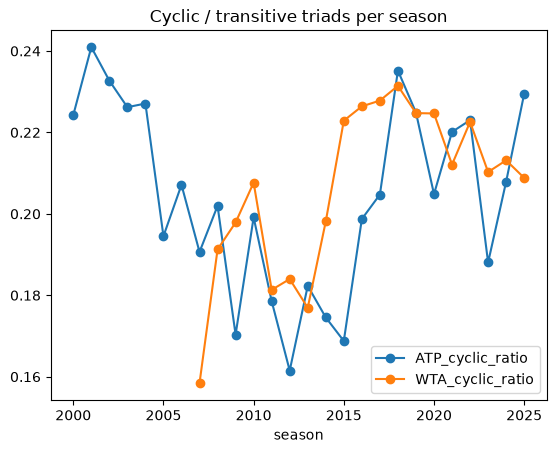

In [8]:
run("triads")
display(table("triads_networks.csv")[["network", "cyclic_ratio", "null_mean", "z", "p_empirical"]])
display(table("triads_h5.csv"))
table("triads_by_season.csv", index_col="season").plot(marker="o", title="Cyclic / transitive triads per season");

## 7. Hypotheses at the monadic, dyadic and mixed levels (slide L04)

* H6 (monadic): PageRank explains the ranking beyond the number of wins (permutation regression)
* H7 (dyadic): head-to-head dominance carries over between surfaces (QAP)
* H8 (mixed): players with the same surface profile meet more often (QAP)

In [9]:
run("levels")
display(table("levels_tests.csv"))
profiles = table("surface_profiles.csv", index_col="player")
display(profiles["profile"].value_counts())

[levels] (using precomputed results)


,hypothesis,level,comparison,statistic,value,p_value,n,note
0,H6,monadic,td_atp_2000_2006: log(ranking) on log(PageRank...,beta log PageRank,-0.631,0.001,524,R2 = 0.611
1,H6,monadic,td_atp_2000_2006: log(ranking) on log(PageRank...,beta log wins,-0.154,0.415,524,R2 = 0.611
2,H6,monadic,td_atp_2007_2012: log(ranking) on log(PageRank...,beta log PageRank,-0.773,0.001,423,R2 = 0.758
3,H6,monadic,td_atp_2007_2012: log(ranking) on log(PageRank...,beta log wins,-0.101,0.593,423,R2 = 0.758
4,H6,monadic,td_atp_2013_2018: log(ranking) on log(PageRank...,beta log PageRank,-0.859,0.001,393,R2 = 0.758
5,H6,monadic,td_atp_2013_2018: log(ranking) on log(PageRank...,beta log wins,-0.012,0.951,393,R2 = 0.758
6,H6,monadic,td_atp_2019_2025: log(ranking) on log(PageRank...,beta log PageRank,-0.725,0.001,442,R2 = 0.729
7,H6,monadic,td_atp_2019_2025: log(ranking) on log(PageRank...,beta log wins,-0.132,0.505,442,R2 = 0.729
8,H7,dyadic,"head-to-head balance on Clay vs on Hard, ATP 2...",QAP Pearson r,0.149,0.001,328,mean permuted r = 0.000
9,H7,dyadic,"head-to-head balance on Grass vs on Hard, ATP ...",QAP Pearson r,0.123,0.001,306,mean permuted r = 0.000


profile
all-round    204
clay          76
hard          48
Name: count, dtype: int64

## 8. Report tables, figures and word count

[report_assets] (using precomputed results)
[wordcount] (using precomputed results)


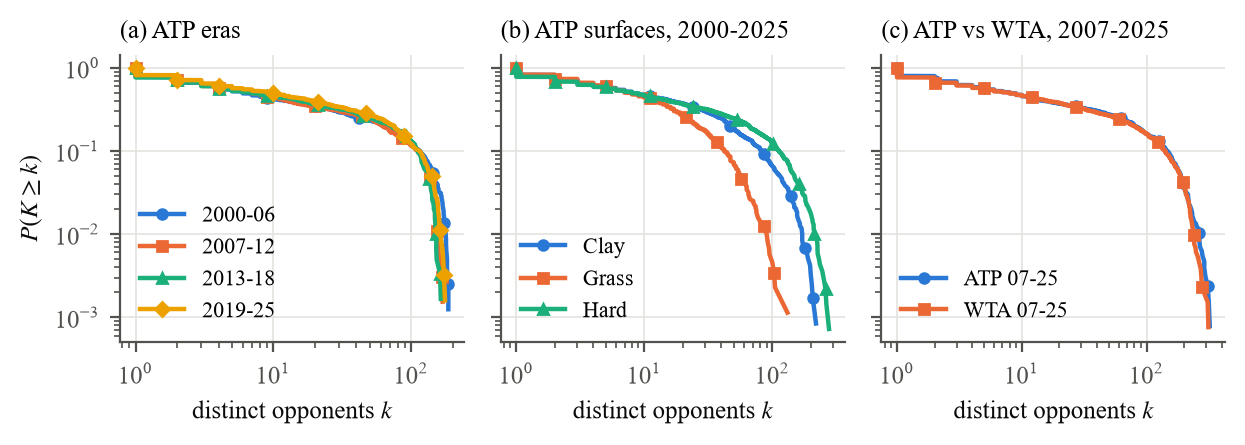

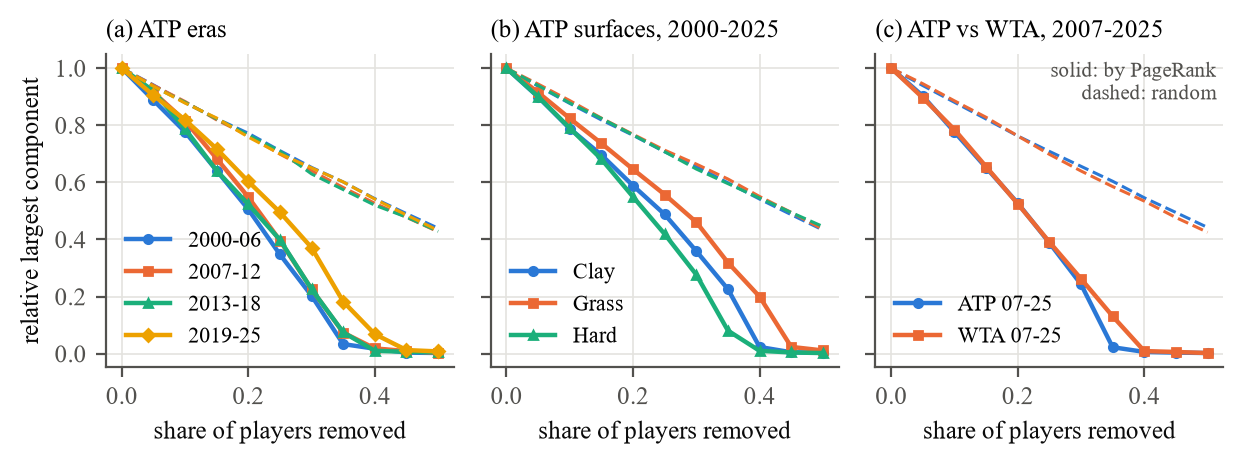

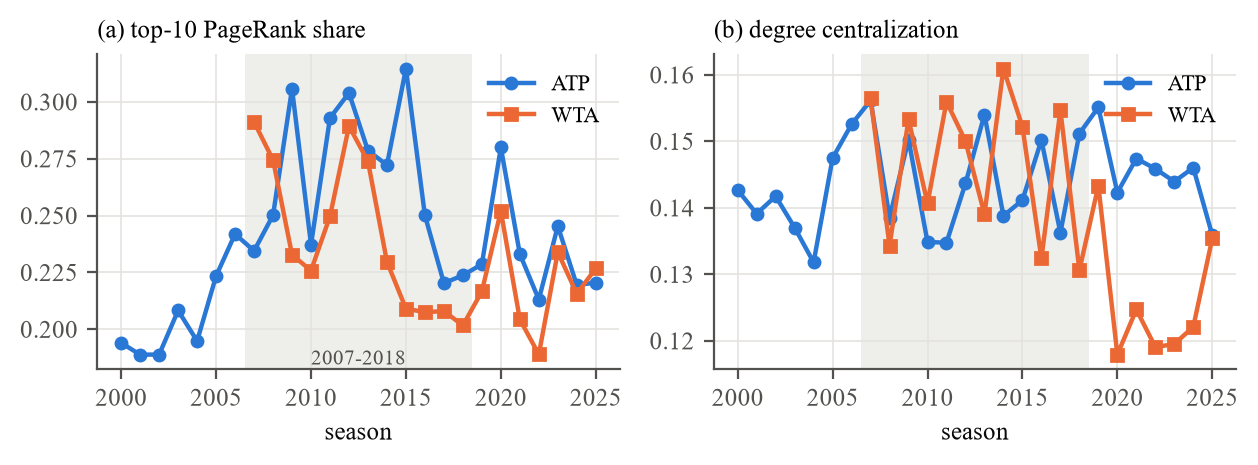

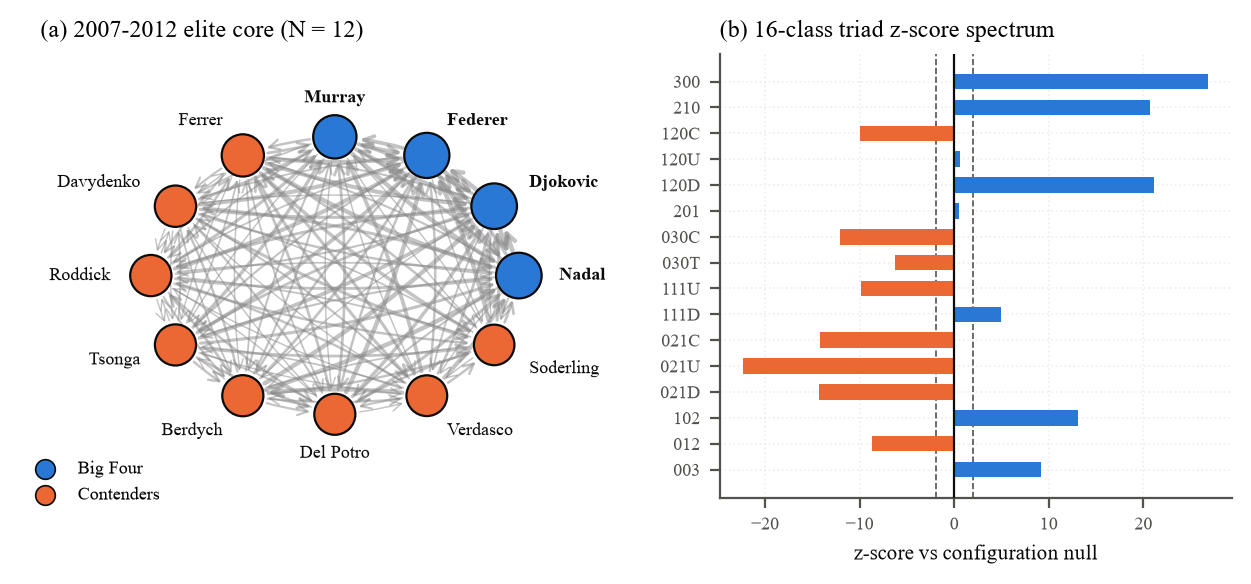

In [10]:
run("report_assets")
run("wordcount")
for name in ("fig_degree_ccdf", "fig_robustness", "fig_yearly", "fig_network_core_2007_2012"):
    display(Image(filename=str(REPORT / "figures" / f"{name}.png")))

## 9. Summary of all hypotheses

In [11]:
h = table("hypothesis_tests.csv")
h5 = table("triads_h5.csv")
lv = table("levels_tests.csv")
summary = pd.concat(
    [
        h[["hypothesis", "statistic", "comparison", "value_a", "value_b", "p_value"]],
        h5[["hypothesis", "statistic", "comparison", "value_a", "value_b", "p_value"]],
        lv.rename(columns={"value": "value_a"})[["hypothesis", "statistic", "comparison", "value_a", "p_value"]],
    ],
    ignore_index=True,
)
display(summary)
display(Markdown(f"Results written to `{TABLES}` and `{REPORT}`. Check `git diff --stat` before committing."))

,hypothesis,statistic,comparison,value_a,value_b,p_value
0,H1,top10_pagerank_share,ATP 2007-2018 vs 2019-2025 (season means),0.265,0.234,0.060
1,H1,degree_centralization,ATP 2007-2018 vs 2019-2025 (season means),0.144,0.145,0.757
2,H2,degree_assortativity,td_atp_2000_2006 vs configuration model,-0.031,-0.183,0.005
3,H2,degree_assortativity,td_atp_2007_2012 vs configuration model,-0.036,-0.187,0.005
4,H2,degree_assortativity,td_atp_2013_2018 vs configuration model,-0.036,-0.175,0.005
5,H2,degree_assortativity,td_atp_2019_2025 vs configuration model,-0.022,-0.173,0.005
6,H2,degree_assortativity,td_atp_clay vs configuration model,0.020,-0.108,0.005
7,H2,degree_assortativity,td_atp_grass vs configuration model,0.098,-0.061,0.005
8,H2,degree_assortativity,td_atp_hard vs configuration model,0.033,-0.118,0.005
9,H2,degree_assortativity,td_wta_2007_2025 vs configuration model,0.020,-0.146,0.005


Results written to `D:\Actual\03_Sviluppo_Software\Repositories\tennis-network-analysis\results\tables` and `D:\Actual\03_Sviluppo_Software\Repositories\tennis-network-analysis\report`. Check `git diff --stat` before committing.